# Water Rights Restored to the Gila River

The impacts of irrigation on vegetation health in the Gila River Valley


## Set up

To get started on this notebook, you’ll need to restore any variables from previous notebooks to your workspace. To save time and memory, make sure to specify which variables you want to load.

In [1]:
%store -r ndvi_ds gila_river_gdf


You will also need to import any libraries you are using in this
notebook, since they won’t carry over from the previous notebook:

In [2]:
### import libraries
import geopandas as gpd
import matplotlib.pyplot as plt
import rioxarray as rxr
import hvplot.pandas
import holoviews as hv
from IPython.display import FileLink, display

# Keep the boundary name used in the template.
your_gdf = gila_river_gdf


## Step 5: Is the mean annual July NDVI different within the Gila River Indian Community after the change in water rights?

You will compute the mean NDVI inside and outside the Reservation boundary. 

### Step 5A: Get the NDVI inside and outside the Gila River Indian Community

First, use the code below to get a `GeoDataFrame` of the area outside the Reservation.

- Check the variable names. Make sure that the code uses your boundary `GeoDataFrame`  
- How could you test if the geometry was modified correctly? Add some code to take a look at the results

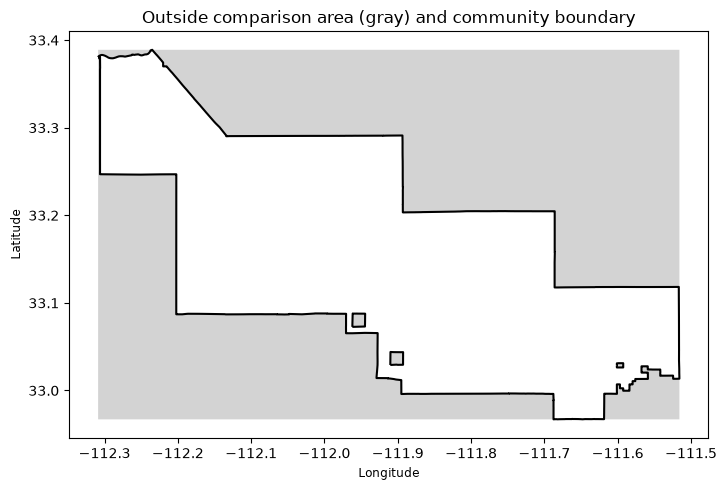

In [3]:
### compute the area outside the community but inside its bounding rectangle
out_gdf = gpd.GeoDataFrame(
    geometry=your_gdf.envelope, crs=your_gdf.crs
).overlay(your_gdf, how='difference')

### check the geometry visually
ax = out_gdf.plot(color='lightgray', figsize=(8, 5), label='Outside')
your_gdf.boundary.plot(ax=ax, color='black')
ax.set_title('Outside comparison area (gray) and community boundary')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.tight_layout()
plt.show()


Next, clip your DataArray to the boundaries for both inside and outside
the reservation. You will need to replace the `GeoDataFrame` name with
your own. Check out the [lesson on clipping data with the `rioxarray`
library on EarthDataScience.org](https://www.earthdatascience.org/courses/use-data-open-source-python/intro-raster-data-python/raster-data-processing/crop-raster-data-with-shapefile-in-python/).

**Note**: It’s important to use `from_disk = True` when clipping large arrays like this. It allows the computer to use less valuable memory resources when clipping. Otherwise, you will probably find that the cell below crashes your kernel.

In this series, notebook 03 already loaded and combined the rasters in memory.
`from_disk=True` only saves memory when a file-backed raster is available; it does not make this combined dataset file-backed.


In [4]:
### clip data to inside the community boundary
ndvi_inside = ndvi_ds.rio.clip(
    your_gdf.geometry.values, your_gdf.crs, from_disk=True
)

### clip data to outside the community boundary
ndvi_outside = ndvi_ds.rio.clip(
    out_gdf.geometry.values, out_gdf.crs, from_disk=True
)


### Step 5B: Assess the change in NDVI before and after the change in water rights, inside and outside the boundaries of the Gila River Indian Community

For **both inside and outside** the Gila River Indian Community boundary, calculate the mean annual July NDVI:  

- Group the data by year  
- Take the mean. You always need to tell reducing methods in `xarray` what dimensions you want to reduce. When you want to summarize data across **all** dimensions, you can use the `...` syntax, e.g. `.mean(...)` as a shorthand  
- Select the NDVI variable  
- Convert to a DataFrame using the `to_dataframe()` method  
- Join the two DataFrames for plotting using the `.join()` method. You will need to rename the columns using the `lsuffix =` and `rsuffix =` parameters
- Finally, plot annual July means for both inside and outside the Reservation on the same plot.

**Note**: The DateIndex in pandas is a little different from the Datetime Dimension in xarray. You will need to use the `.dt.year` syntax to access information about the year, not just `.year`.


These plots describe July NDVI patterns. The outside area is a local comparison, not a matched control; differences alone do not establish the effect of water rights.


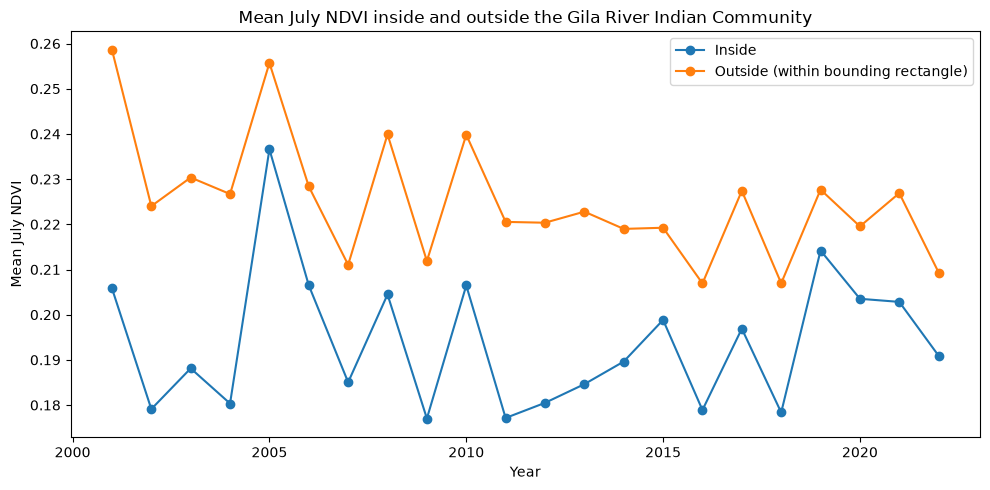

c:\Users\gekek\Documents\03-vegetation-fall-template\notebooks\july-ndvi.html

In [5]:
### calculate mean annual July NDVI inside
july_inside = ndvi_inside.sel(date=ndvi_inside.date.dt.month == 7)
inside_df = (
    july_inside.groupby('date.year').mean(dim=...).NDVI
    .to_dataframe()[['NDVI']]
)

### calculate mean annual July NDVI outside
july_outside = ndvi_outside.sel(date=ndvi_outside.date.dt.month == 7)
outside_df = (
    july_outside.groupby('date.year').mean(dim=...).NDVI
    .to_dataframe()[['NDVI']]
)

### join the annual means into one table
annual_ndvi_df = inside_df.join(
    outside_df, lsuffix='_inside', rsuffix='_outside'
)

### plot inside and outside on a single plot
ax = annual_ndvi_df.plot(marker='o', figsize=(10, 5))
ax.set_title('Mean July NDVI inside and outside the Gila River Indian Community')
ax.set_xlabel('Year')
ax.set_ylabel('Mean July NDVI')
ax.legend(['Inside', 'Outside (within bounding rectangle)'])
plt.tight_layout()
plt.show()

### make an interactive version that opens without notebook widgets
annual_ndvi_map = annual_ndvi_df.hvplot.line(
    xlabel='Year', ylabel='Mean July NDVI',
    title='July vegetation greenness inside and outside the community',
    frame_width=700
)
hv.save(annual_ndvi_map, 'july-ndvi.html', resources='inline')
display(FileLink('july-ndvi.html', result_html_prefix='Interactive annual plot: '))


Now, take the difference between outside and inside the site boundary and plot that


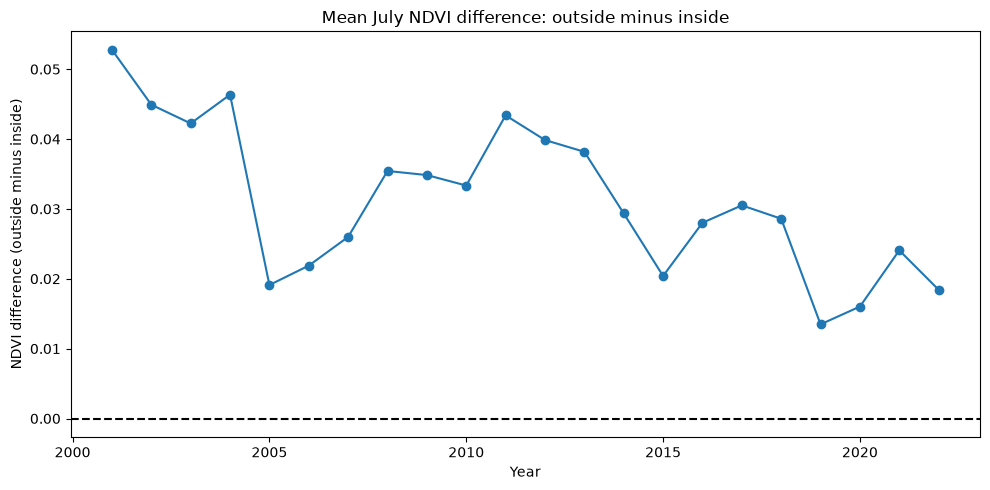

c:\Users\gekek\Documents\03-vegetation-fall-template\notebooks\july-ndvi-difference.html

In [6]:
### calculate outside minus inside, as requested
ndvi_difference_df = annual_ndvi_df[['NDVI_outside']].copy()
ndvi_difference_df['outside_minus_inside'] = (
    annual_ndvi_df['NDVI_outside'] - annual_ndvi_df['NDVI_inside']
)
ndvi_difference_df = ndvi_difference_df[['outside_minus_inside']]

### positive means outside is greener; negative means inside is greener
ax = ndvi_difference_df.plot(
    marker='o', legend=False, figsize=(10, 5)
)
ax.axhline(0, color='black', linestyle='--')
ax.set_title('Mean July NDVI difference: outside minus inside')
ax.set_xlabel('Year')
ax.set_ylabel('NDVI difference (outside minus inside)')
plt.tight_layout()
plt.show()

### save an interactive version
ndvi_difference_plot = ndvi_difference_df.hvplot.line(
    xlabel='Year', ylabel='NDVI difference (outside minus inside)',
    title='July NDVI difference: positive = outside greener',
    frame_width=700
)
hv.save(ndvi_difference_plot, 'july-ndvi-difference.html', resources='inline')
display(FileLink('july-ndvi-difference.html', result_html_prefix='Interactive difference plot: '))


### Reflect and Respond #6:
What do you observe? Don’t forget to write a headline and description of your plot!

## Wrap up

Don’t forget to store your variables so you can use them in other notebooks! Replace `var1` and `var2` with the variable you want to save, separated by spaces.

In [7]:
%store ndvi_inside ndvi_outside annual_ndvi_df ndvi_difference_df


Stored 'ndvi_inside' (Dataset)
Stored 'ndvi_outside' (Dataset)
Stored 'annual_ndvi_df' (DataFrame)
Stored 'ndvi_difference_df' (DataFrame)


Finally, be sure to `Restart` and `Run all` to make sure your notebook
works all the way through!